# Laugh vs Choke - AudioCNN v4
שיפורים: Stratified split · Global Avg Pooling · נרמול קלט · Dropout2d · Batch=16 · LR Scheduler · Early Stopping

In [ ]:
import os
import json
import random
import numpy as np
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR   = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")
PROCESSED_DIR = PROJECT_DIR / "processed"

META_PATH      = PROCESSED_DIR / "meta.json"
NORM_PATH      = PROCESSED_DIR / "norm_stats.json"
MANIFEST_PATH  = PROCESSED_DIR / "manifest.json"

with open(META_PATH, "r") as f:
    meta = json.load(f)

with open(NORM_PATH, "r") as f:
    norm_stats = json.load(f)

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

CHANNEL_NAMES = meta["channels"]
N_CHANNELS    = meta["n_channels"]
HEIGHT, WIDTH = meta["tensor_shape"][1], meta["tensor_shape"][2]

CLASS_NAMES   = ["choking", "laughter"]
NUM_CLASSES   = len(CLASS_NAMES)
class_to_idx  = {name: i for i, name in enumerate(CLASS_NAMES)}

print("Channels:", CHANNEL_NAMES)
print("Number of channels:", N_CHANNELS)
print("Input shape:", (N_CHANNELS, HEIGHT, WIDTH))
print("Classes:", class_to_idx)

print("\nManifest original-file counts:")
for split in ["train", "val", "test"]:
    print(split, manifest["counts"][split])

Channels: ['log_mel', 'harmonic_mel', 'percussive_mel', 'delta', 'delta_delta', 'zcr', 'rms', 'spectral_centroid', 'spectral_rolloff', 'spectral_bandwidth', 'spectral_contrast', 'chroma', 'mfcc', 'tonnetz', 'spectral_flatness', 'f0', 'voiced_prob', 'spectral_flux', 'wide_band_mel', 'rms_periodicity']
Number of channels: 20
Input shape: (20, 128, 128)
Classes: {'choking': 0, 'laughter': 1}

Manifest original-file counts:
train {'choking': 88, 'laughter': 72}
val {'choking': 17, 'laughter': 23}
test {'choking': 34, 'laughter': 25}


In [ ]:
def collect_split_samples(split_name):
    split_dir = PROCESSED_DIR / split_name
    samples = []

    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        label = class_to_idx[class_name]

        for file_path in sorted(class_dir.glob("*.npy")):
            samples.append((file_path, label))

    return samples


train_samples = collect_split_samples("train")
val_samples   = collect_split_samples("val")
test_samples  = collect_split_samples("test")


def print_split_summary(split_name, samples):
    counts = {class_name: 0 for class_name in CLASS_NAMES}

    for _, label in samples:
        class_name = CLASS_NAMES[label]
        counts[class_name] += 1

    print(f"{split_name}: {len(samples)} tensors")
    for class_name in CLASS_NAMES:
        print(f"  {class_name}: {counts[class_name]}")


print("\nTensor counts after preprocessing:")
print_split_summary("Train", train_samples)
print_split_summary("Val", val_samples)
print_split_summary("Test", test_samples)


Tensor counts after preprocessing:
Train: 640 tensors
  choking: 352
  laughter: 288
Val: 80 tensors
  choking: 34
  laughter: 46
Test: 59 tensors
  choking: 34
  laughter: 25


## 1. Dataset עם נרמול קלט
נרמול per-sample מייצב את האימון ומקל על המודל

In [ ]:
class AudioFeatureDataset(Dataset):
    def __init__(self, samples, norm_stats):
        self.samples = samples

        self.mean = np.array(
            norm_stats["mean"],
            dtype=np.float32
        )[:, None, None]

        self.std = np.array(
            norm_stats["std"],
            dtype=np.float32
        )[:, None, None]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_path, label = self.samples[idx]

        x = np.load(file_path).astype(np.float32)

        # Per-channel z-score using TRAIN statistics
        x = (x - self.mean) / self.std

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(label, dtype=torch.long)
        )
train_dataset = AudioFeatureDataset(
    train_samples,
    norm_stats
)

val_dataset = AudioFeatureDataset(
    val_samples,
    norm_stats
)

test_dataset = AudioFeatureDataset(
    test_samples,
    norm_stats
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

## 2. Multi-Branch Architecture
בדיוק כפי שמתואר בפוסטר — Tonal / Transient / Energy branches

In [ ]:
class BranchCNN(nn.Module):
    """
    Branch קטן ומינימליסטי — מותאם לדאטה קטן.
    2 שכבות Conv בלבד + AdaptiveAvgPool → פחות פרמטרים, פחות overfitting.
    """
    def __init__(self, in_channels, out_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.AdaptiveAvgPool2d(1),  # → (batch, 32, 1, 1)
        )
        self.fc = nn.Linear(32, out_dim)

    def forward(self, x):
        x = self.net(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class MultiBranchAudioCNN(nn.Module):
    """
    Multi-Fusion CNN מינימליסטי — מותאם ל-400 דוגמאות.

    3 branches קטנים (32 dim כל אחד) → Fusion (96) → classifier פשוט.

    Channel indices:
      Tonal:     [0,1,11,12,13,15,16]  log_mel, harmonic_mel, chroma, mfcc, tonnetz, f0, voiced_prob
      Transient: [2,3,4,17,18]         percussive_mel, delta, delta_delta, spectral_flux, wide_band_mel
      Energy:    [5,6,7,8,9,10,14,19]  zcr, rms, centroid, rolloff, bandwidth, contrast, flatness, rms_periodicity
    """
    TONAL_NAMES = [
         "log_mel", "harmonic_mel", "chroma", "mfcc", "tonnetz", "f0", "voiced_prob"
    ]

    TRANSIENT_NAMES = [
        "percussive_mel", "delta", "delta_delta",
        "spectral_flux", "wide_band_mel"
    ]

    ENERGY_NAMES = [
        "zcr", "rms", "spectral_centroid", "spectral_rolloff", "spectral_bandwidth", "spectral_contrast", "spectral_flatness", "rms_periodicity"
    ]

    TONAL_IDX     = [CHANNEL_NAMES.index(name) for name in TONAL_NAMES]
    TRANSIENT_IDX = [CHANNEL_NAMES.index(name) for name in TRANSIENT_NAMES]
    ENERGY_IDX    = [CHANNEL_NAMES.index(name) for name in ENERGY_NAMES]

    def __init__(self, num_classes=2, branch_dim=32):
        super().__init__()
        self.tonal_branch     = BranchCNN(len(self.TONAL_IDX),     branch_dim)
        self.transient_branch = BranchCNN(len(self.TRANSIENT_IDX), branch_dim)
        self.energy_branch    = BranchCNN(len(self.ENERGY_IDX),    branch_dim)

        fusion_in = branch_dim * 3  # 96
        self.classifier = nn.Sequential(
            nn.Linear(fusion_in, 48),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(48, num_classes)
        )

    def forward(self, x):
        t  = self.tonal_branch    (x[:, self.TONAL_IDX,     :, :])
        tr = self.transient_branch(x[:, self.TRANSIENT_IDX, :, :])
        e  = self.energy_branch   (x[:, self.ENERGY_IDX,    :, :])

        fused = torch.cat([t, tr, e], dim=1)  # (batch, 96)
        return self.classifier(fused)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = MultiBranchAudioCNN(num_classes=NUM_CLASSES).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")


Using device: cuda
Total trainable parameters: 25,058


## 3. Training & Evaluation Functions

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        outputs = model(x)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

        preds = torch.argmax(outputs, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return total_loss / max(total, 1), correct / max(total, 1)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * x.size(0)

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    return total_loss / max(total, 1), correct / max(total, 1), all_preds, all_labels

## 4. אימון עם Early Stopping + LR Scheduler

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-3)

# מוריד LR כשהval_loss לא משתפר 3 epochs ברציפות
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=4, factor=0.5
)

NUM_EPOCHS = 15
PATIENCE   = 8

best_model_path = PROJECT_DIR / "best_audio_cnn_v4.pth"
best_val_loss   = float('inf')
counter         = 0

train_losses, val_losses = [], []
train_accs,   val_accs   = [], []

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss,   val_acc, _, _ = evaluate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        counter = 0
        print("  ✓ Model saved!")
    else:
        counter += 1
        if counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

model.load_state_dict(torch.load(best_model_path))
print("\nBest model loaded.")

Epoch [01/15] Train Loss: 0.6820 | Train Acc: 0.5609 | Val Loss: 0.6725 | Val Acc: 0.7625LR: 0.000500
  ✓ Model saved!
Epoch [02/15] Train Loss: 0.6313 | Train Acc: 0.6984 | Val Loss: 0.5883 | Val Acc: 0.8125LR: 0.000500
  ✓ Model saved!
Epoch [03/15] Train Loss: 0.5515 | Train Acc: 0.7828 | Val Loss: 0.4974 | Val Acc: 0.8000LR: 0.000500
  ✓ Model saved!
Epoch [04/15] Train Loss: 0.4576 | Train Acc: 0.8141 | Val Loss: 0.4117 | Val Acc: 0.8750LR: 0.000500
  ✓ Model saved!
Epoch [05/15] Train Loss: 0.4200 | Train Acc: 0.8281 | Val Loss: 0.3817 | Val Acc: 0.8500LR: 0.000500
  ✓ Model saved!
Epoch [06/15] Train Loss: 0.3820 | Train Acc: 0.8516 | Val Loss: 0.3403 | Val Acc: 0.8750LR: 0.000500
  ✓ Model saved!
Epoch [07/15] Train Loss: 0.3861 | Train Acc: 0.8281 | Val Loss: 0.3880 | Val Acc: 0.8375LR: 0.000500
Epoch [08/15] Train Loss: 0.3471 | Train Acc: 0.8641 | Val Loss: 0.3556 | Val Acc: 0.8625LR: 0.000500
Epoch [09/15] Train Loss: 0.3303 | Train Acc: 0.8562 | Val Loss: 0.3805 | Val Acc:

## 5. גרפים

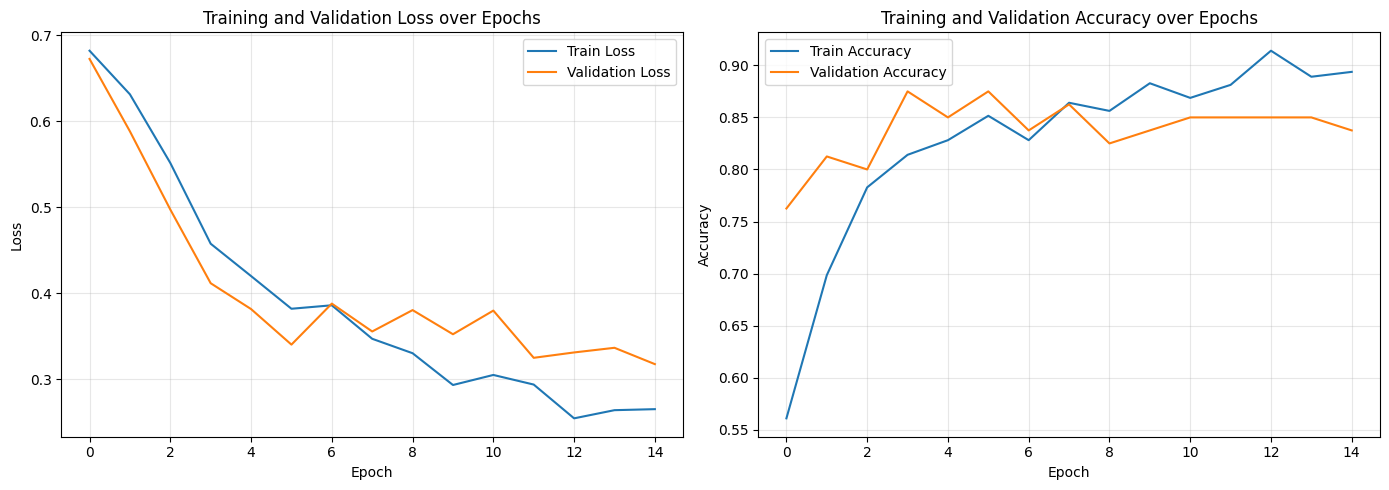

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses,   label="Validation Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.set_title("Training and Validation Loss over Epochs")
ax1.grid(True, alpha=0.3)

ax2.plot(train_accs, label="Train Accuracy")
ax2.plot(val_accs,   label="Validation Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.set_title("Training and Validation Accuracy over Epochs")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. הערכה על Test Set

In [ ]:
test_loss, test_acc, test_preds, test_labels = evaluate(model, test_loader, criterion, device)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print()
print(classification_report(test_labels, test_preds, target_names=CLASS_NAMES))

Test Loss:     0.3080
Test Accuracy: 0.8644

              precision    recall  f1-score   support

     choking       0.93      0.82      0.88        34
    laughter       0.79      0.92      0.85        25

    accuracy                           0.86        59
   macro avg       0.86      0.87      0.86        59
weighted avg       0.87      0.86      0.87        59



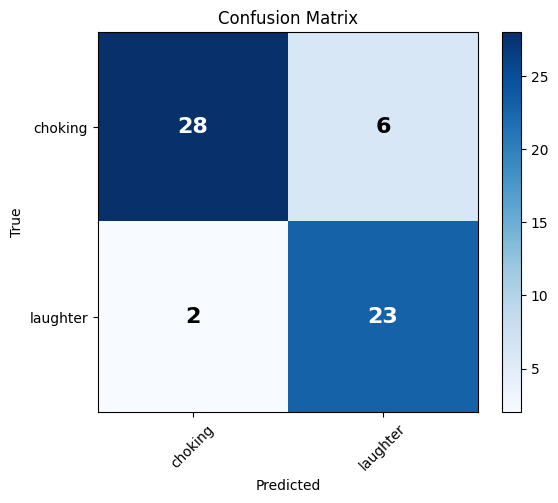

In [ ]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.colorbar()

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. שמירת המודל

In [ ]:
SAVE_PATH = PROJECT_DIR / "audio_cnn_v4.pth"

torch.save({
    "model_state_dict": model.state_dict(),

    "class_names": CLASS_NAMES,
    "channel_names": CHANNEL_NAMES,

    "n_channels": N_CHANNELS,
    "input_shape": (N_CHANNELS, HEIGHT, WIDTH),

    "norm_mean": norm_stats["mean"],
    "norm_std": norm_stats["std"],

    "model_type": "MultiBranchAudioCNN",
    "branch_dim": 32
}, SAVE_PATH)

print("Model saved to:", SAVE_PATH)

Model saved to: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/audio_cnn_v4_final.pth
